# Imports:

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
plt.style.use("default")
plt.rcParams["figure.dpi"] = 72

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from torch.nn import init
from torch.optim import Adam, AdamW, SGD
from torch.optim.lr_scheduler import ReduceLROnPlateau
from copy import deepcopy

# Dataset:

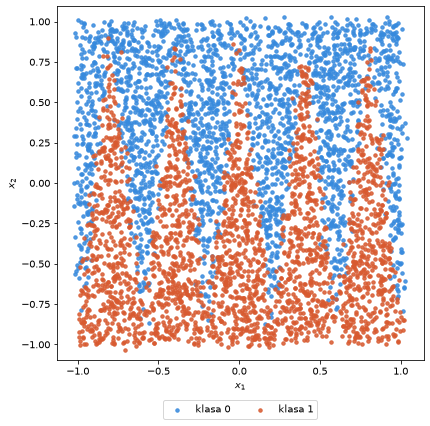

In [2]:
def triangle_wave(t):
    return 2 * np.abs(2 * (t - np.floor(t + 0.5))) - 1

def make_teeth(n=5000, teeth=5, amp=0.9, noise=0.06, seed=42):
    rng = np.random.default_rng(seed)
    X = rng.uniform(-1, 1, size=(n, 2))
    boundary = amp * triangle_wave(teeth * (X[:, 0] + 1) / 2)
    y = (X[:, 1] <= boundary).astype(int)
    X = X + rng.normal(0, noise * 0.3, size=X.shape)

    return X, y


X, y = make_teeth(n=5000, teeth=5, amp=0.9, noise=0.06)


plt.figure(figsize=(6, 6))
plt.scatter(X[y == 0, 0], X[y == 0, 1], s=12, c="#378ADD", alpha=0.85, label="klasa 0")
plt.scatter(X[y == 1, 0], X[y == 1, 1], s=12, c="#D85A30", alpha=0.85, label="klasa 1")
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.axis("equal")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
plt.tight_layout()
plt.savefig("spikes.png", dpi=150)
plt.show()

# SPLIT Train/Val/Testttt


In [3]:
X_train, X_hold, y_train, y_hold = train_test_split(X, y, test_size=0.4, stratify=y ,random_state=42)

X_val, X_test, y_val, y_test = train_test_split(X_hold, y_hold, test_size=0.5, stratify=y_hold, random_state=42)

y_train = y_train.astype("float32").reshape(-1, 1)
y_val = y_val.astype("float32").reshape(-1, 1)
y_test = y_test.astype("float32").reshape(-1, 1)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

print("Trening / walidacja / test:", len(X_train), len(X_val), len(X_test))
print(X_train.shape, X_val.shape, X_test.shape)
print(y_train.shape, y_val.shape, y_test.shape)

Trening / walidacja / test: 3000 1000 1000
(3000, 2) (1000, 2) (1000, 2)
(3000, 1) (1000, 1) (1000, 1)


# Building a Dense Neural Network

In [4]:
RUN_NAME = "Final_configuration"
output_dir = Path("Model_variants") / RUN_NAME
output_dir.mkdir(parents=True, exist_ok=True)

torch.manual_seed(2026)

model = nn.Sequential(

    nn.Linear(2, 128),
    nn.ReLU(),

    nn.Linear(128, 128),
    nn.ReLU(),

    nn.Linear(128, 128),
    nn.ReLU(),

    nn.Linear(128, 1),
)

# model =nn.Linear(2,1)

hidden_layer_indices = [0,2,4]

for index in hidden_layer_indices:
    layer = model[index]

    nn.init.kaiming_normal_(layer.weight, mode="fan_in", nonlinearity="relu")
    nn.init.zeros_(layer.bias)


output_layer = model[6]

nn.init.xavier_uniform_(output_layer.weight)
nn.init.zeros_(output_layer.bias)

# nn.init.zeros_(model.weight)
# nn.init.zeros_(model.bias)

number_of_params = sum(parameter.numel() for parameter in model.parameters())
print(number_of_params)

33537


# Defining the Training Method

In [5]:
optimizer = AdamW(
    model.parameters(),
    lr=0.001,
    weight_decay=0.1
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=10, min_lr=1e-5
)

loss_fn = nn.BCEWithLogitsLoss()

# Preparing Data for PyTorch

In [6]:
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32)

X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val, dtype=torch.float32)

X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)


train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
)

# Evaluation Function

In [7]:
def evaluate_bianry_classifier(model, X, y, loss_fn):
    model.eval()

    with torch.no_grad():
        logits = model(X)
        loss = loss_fn(logits, y).item()
        probs = torch.sigmoid(logits)
        preds = (probs >= 0.5).long()
        accuracy = (preds == y.long()).float().mean().item()

    return {
        "loss": loss,
        "accuracy": accuracy,
    }

# Trening

In [8]:
number_of_epochs = 200

history = []
best_epoch = None
best_model_state = None
best_val_loss = float("inf")

for epoch in range(1, number_of_epochs + 1):
    model.train()

    for xb, yb in train_loader:

        optimizer.zero_grad()
        logits = model(xb)
        loss = loss_fn(logits, yb)
        loss.backward()
        optimizer.step()


    train_result = evaluate_bianry_classifier(model, X_train_tensor, y_train_tensor, loss_fn)
    train_loss = train_result["loss"]

    val_result = evaluate_bianry_classifier(model, X_val_tensor, y_val_tensor, loss_fn)
    scheduler.step(val_result["loss"])

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_result["loss"],
        "val_accuracy": val_result["accuracy"],
    })

    if val_result["loss"] < best_val_loss:
        best_val_loss =  val_result["loss"]
        best_epoch = epoch
        best_model_state = deepcopy(model.state_dict())

    print(
    f"Epoka {epoch:2d}/{number_of_epochs} | "
    f"train loss: {train_loss:.4f} | "
    f"val loss: {val_result['loss']:.4f} | "
    f"val accuracy: {val_result['accuracy']:.4f}"
    )


model.load_state_dict(best_model_state)
model.eval()

print("Najlepsza epoka:", best_epoch)
print("Najmniejsze BCE walidacyjne:", best_val_loss)

Epoka  1/200 | train loss: 0.4657 | val loss: 0.4290 | val accuracy: 0.7990
Epoka  2/200 | train loss: 0.4542 | val loss: 0.4135 | val accuracy: 0.8050
Epoka  3/200 | train loss: 0.4590 | val loss: 0.4273 | val accuracy: 0.8050
Epoka  4/200 | train loss: 0.4496 | val loss: 0.4059 | val accuracy: 0.8180
Epoka  5/200 | train loss: 0.4479 | val loss: 0.4089 | val accuracy: 0.8070
Epoka  6/200 | train loss: 0.4371 | val loss: 0.4024 | val accuracy: 0.8090
Epoka  7/200 | train loss: 0.4381 | val loss: 0.3971 | val accuracy: 0.8150
Epoka  8/200 | train loss: 0.4299 | val loss: 0.3909 | val accuracy: 0.8180
Epoka  9/200 | train loss: 0.4289 | val loss: 0.3955 | val accuracy: 0.8110
Epoka 10/200 | train loss: 0.4311 | val loss: 0.4096 | val accuracy: 0.8070
Epoka 11/200 | train loss: 0.4212 | val loss: 0.3889 | val accuracy: 0.8280
Epoka 12/200 | train loss: 0.4243 | val loss: 0.3903 | val accuracy: 0.8130
Epoka 13/200 | train loss: 0.4143 | val loss: 0.3864 | val accuracy: 0.8260
Epoka 14/200

# Training History Plot

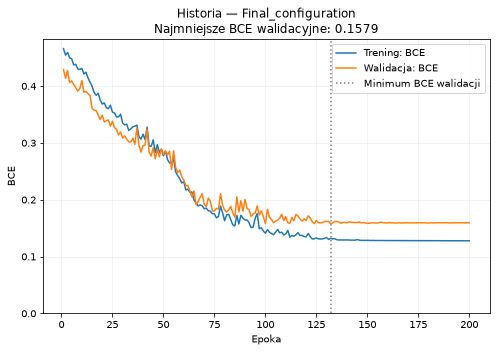

In [9]:
epochs = [result["epoch"] for result in history]
train_losses = [result["train_loss"] for result in history]
val_losses = [result["val_loss"] for result in history]
best_epoch_index = np.argmin(val_losses)
best_epoch = epochs[best_epoch_index]
best_val_loss = val_losses[best_epoch_index]
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(epochs,train_losses,label="Trening: BCE",)
ax.plot(epochs,val_losses, label="Walidacja: BCE")
ax.axvline(best_epoch, color="gray", linestyle=":", label="Minimum BCE walidacji")
ax.set(xlabel="Epoka", ylabel="BCE", title=f"Historia — {RUN_NAME}\n"f"Najmniejsze BCE walidacyjne: {best_val_loss:.4f}")
ax.set_ylim(bottom=0)
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()
fig.savefig(output_dir / "history_bce.png",dpi=150,bbox_inches="tight")
plt.show()


# Decision Boundary Plot

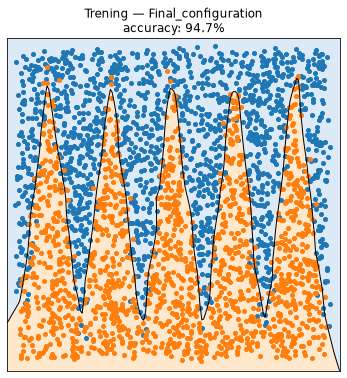

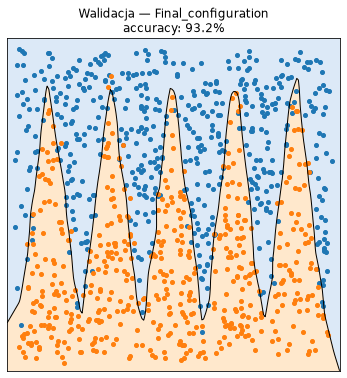

In [10]:
train_scores = evaluate_bianry_classifier(model, X_train_tensor, y_train_tensor, loss_fn)
val_scores = evaluate_bianry_classifier(model, X_val_tensor, y_val_tensor, loss_fn)
X_train_plot = scaler.inverse_transform(X_train)
X_val_plot = scaler.inverse_transform(X_val)

visible = np.vstack([X_train_plot, X_val_plot])
x1 = np.linspace(visible[:, 0].min() - 0.05, visible[:, 0].max() + 0.05, 201)
x2 = np.linspace(visible[:, 1].min() - 0.05, visible[:, 1].max() + 0.05, 201)

grid_x1, grid_x2 = np.meshgrid(x1, x2)
grid = np.column_stack([grid_x1.ravel(), grid_x2.ravel()])
grid_scaled = scaler.transform(grid)
grid_tensor = torch.tensor(grid_scaled, dtype=torch.float32)

model.eval()

with torch.no_grad():
    probability = torch.sigmoid(model(grid_tensor)).numpy().reshape(grid_x1.shape)

def plot_boundary(X_points, y_points, title, filename):
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.contourf(grid_x1, grid_x2, probability, levels=[0, 0.5, 1], colors=["#dce9f7", "#ffe8cc"])
    ax.contour(grid_x1, grid_x2, probability,levels=[0.5],colors="black",linewidths=1,)
    ax.scatter(X_points[y_points.ravel() == 0, 0], X_points[y_points.ravel() == 0, 1], s=16, color="tab:blue")
    ax.scatter(X_points[y_points.ravel() == 1, 0], X_points[y_points.ravel() == 1, 1], s=16,color="tab:orange",)
    ax.set_title(title)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    fig.savefig(output_dir / filename, dpi=150, bbox_inches="tight")
    plt.show()

plot_boundary(
    X_train_plot,
    y_train,
    f"Trening — {RUN_NAME}\naccuracy: {train_scores['accuracy']:.1%}",
    "granica_decyzji_trening.png",
)

plot_boundary(
    X_val_plot,
    y_val,
    f"Walidacja — {RUN_NAME}\naccuracy: {val_scores['accuracy']:.1%}",
    "granica_decyzji_walidacja.png",
)



# All Evaluation Metrics and Confusion Matrix on the Test Set

Test BCE:       0.1506
Test accuracy:  0.9400
Test precision: 0.9380
Test recall:    0.9418
Test F1:        0.9399


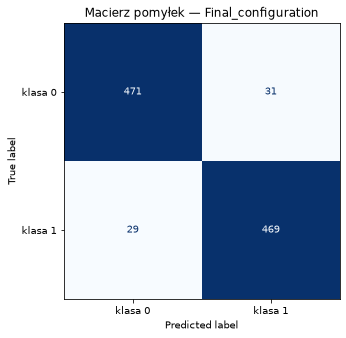

In [11]:
def evaluate_classifier_full(model, X, y, loss_fn):
    model.eval()

    with torch.no_grad():
        logits = model(X)
        loss = loss_fn(logits, y).item()

        probabilities = torch.sigmoid(logits)
        predictions = (probabilities >= 0.5).long()

    y_true = y.cpu().numpy().ravel().astype(int)
    y_pred = predictions.cpu().numpy().ravel().astype(int)

    return {
        "loss": loss,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score( y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "confusion_matrix": confusion_matrix(y_true, y_pred),
        "y_true": y_true,
        "y_pred": y_pred,
    }

test_result = evaluate_classifier_full(model, X_test_tensor, y_test_tensor, loss_fn)

print(f"Test BCE:       {test_result['loss']:.4f}")
print(f"Test accuracy:  {test_result['accuracy']:.4f}")
print(f"Test precision: {test_result['precision']:.4f}")
print(f"Test recall:    {test_result['recall']:.4f}")
print(f"Test F1:        {test_result['f1']:.4f}")

ConfusionMatrixDisplay.from_predictions(
    test_result["y_true"],
    test_result["y_pred"],
    display_labels=["klasa 0", "klasa 1"],
    cmap="Blues",
    colorbar=False,
)

plt.title(f"Macierz pomyłek — {RUN_NAME}")
plt.tight_layout()
plt.savefig(
    output_dir / "confusion_matrix_test.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()